# NOTE
### This notebook is complete work of two data, one tabular data, one image(ultrasonic) data.


# Tabular Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## DATA LOADING
#### There are two datasets one without infertility and one with it so added both and then merged with respect to Patient file no.

In [2]:
df_inf = pd.read_csv("/kaggle/input/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos/PCOS_infertility.csv")
df_woinf = pd.read_excel("/kaggle/input/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos/PCOS_data_without_infertility.xlsx", sheet_name="Full_new")

In [3]:
df = pd.merge(df_woinf,df_inf, on='Patient File No.', suffixes=('','_y'),how='left')

## DATA PREPROCESSING

In [4]:
df.shape

(541, 50)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 50 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Sl. No                    541 non-null    int64  
 1   Patient File No.          541 non-null    int64  
 2   PCOS (Y/N)                541 non-null    int64  
 3    Age (yrs)                541 non-null    int64  
 4   Weight (Kg)               541 non-null    float64
 5   Height(Cm)                541 non-null    float64
 6   BMI                       541 non-null    float64
 7   Blood Group               541 non-null    int64  
 8   Pulse rate(bpm)           541 non-null    int64  
 9   RR (breaths/min)          541 non-null    int64  
 10  Hb(g/dl)                  541 non-null    float64
 11  Cycle(R/I)                541 non-null    int64  
 12  Cycle length(days)        541 non-null    int64  
 13  Marraige Status (Yrs)     540 non-null    float64
 14  Pregnant(Y

### Dataset Structure Overview

The dataset contains **541 patient records** and **50 features** related to clinical, hormonal, lifestyle, and ultrasound parameters used for PCOS diagnosis.

### Key Observations
- Total observations: **541**
- Total features: **50**
- Numerical features dominate the dataset, consisting of both integer and floating-point values.
- The target variable is **PCOS (Y/N)**, indicating whether a patient has Polycystic Ovary Syndrome.
- Most columns contain complete information with very few missing values.
- A small number of columns contain missing values, including:
  - `Marraige Status (Yrs)`
  - `Fast food (Y/N)`
- Some columns such as `Unnamed: 44` and columns ending with `_y` contain mostly or entirely null values and will be removed during preprocessing.
- Features `II beta-HCG(mIU/mL)` and `AMH(ng/mL)` are stored as object data types and require conversion to numeric format before model training.

### Conclusion
The dataset is relatively clean and well-structured. Minor preprocessing steps such as handling missing values, removing redundant columns, and converting object-type features to numeric values are required before exploratory data analysis and machine learning model development.

In [6]:
df.describe()

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Sl. No_y,PCOS (Y/N)_y,I beta-HCG(mIU/mL)_y,II beta-HCG(mIU/mL)_y
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,...,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,0.0,0.0,0.0,0.0
mean,271.000000,271.000000,0.327172,31.430684,59.637153,156.484835,24.311285,13.802218,73.247689,19.243993,...,76.927911,6.129390,6.641405,15.018115,15.451701,8.475915,NaN,NaN,NaN,NaN
std,156.317519,156.317519,0.469615,5.411006,11.028287,6.033545,4.056399,1.840812,4.430285,1.688629,...,5.574112,4.229294,4.436889,3.566839,3.318848,2.165381,NaN,NaN,NaN,NaN
min,1.000000,1.000000,0.000000,20.000000,31.000000,137.000000,12.417882,11.000000,13.000000,16.000000,...,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,136.000000,136.000000,0.000000,28.000000,52.000000,152.000000,21.641274,13.000000,72.000000,18.000000,...,70.000000,3.000000,3.000000,13.000000,13.000000,7.000000,NaN,NaN,NaN,NaN
50%,271.000000,271.000000,0.000000,31.000000,59.000000,156.000000,24.238227,14.000000,72.000000,18.000000,...,80.000000,5.000000,6.000000,15.000000,16.000000,8.500000,NaN,NaN,NaN,NaN
75%,406.000000,406.000000,1.000000,35.000000,65.000000,160.000000,26.634958,15.000000,74.000000,20.000000,...,80.000000,9.000000,10.000000,18.000000,18.000000,9.800000,NaN,NaN,NaN,NaN
max,541.000000,541.000000,1.000000,48.000000,108.000000,180.000000,38.900000,18.000000,82.000000,28.000000,...,100.000000,22.000000,20.000000,24.000000,24.000000,18.000000,NaN,NaN,NaN,NaN


In [7]:
 df.isnull().sum()

Sl. No                        0
Patient File No.              0
PCOS (Y/N)                    0
 Age (yrs)                    0
Weight (Kg)                   0
Height(Cm)                    0
BMI                           0
Blood Group                   0
Pulse rate(bpm)               0
RR (breaths/min)              0
Hb(g/dl)                      0
Cycle(R/I)                    0
Cycle length(days)            0
Marraige Status (Yrs)         1
Pregnant(Y/N)                 0
No. of aborptions             0
  I   beta-HCG(mIU/mL)        0
II    beta-HCG(mIU/mL)        0
FSH(mIU/mL)                   0
LH(mIU/mL)                    0
FSH/LH                        0
Hip(inch)                     0
Waist(inch)                   0
Waist:Hip Ratio               0
TSH (mIU/L)                   0
AMH(ng/mL)                    0
PRL(ng/mL)                    0
Vit D3 (ng/mL)                0
PRG(ng/mL)                    0
RBS(mg/dl)                    0
Weight gain(Y/N)              0
hair gro

### Distribution of PCOS

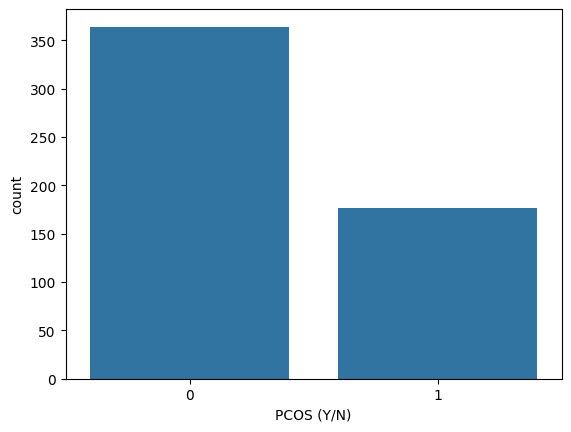

In [8]:
sns.countplot(x='PCOS (Y/N)', data=df)
plt.show()

In [9]:
df['PCOS (Y/N)'].value_counts()

PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

### Majority patients do not have PCOS

In [10]:
df['AMH(ng/mL)'] = pd.to_numeric(
    df['AMH(ng/mL)'],
    errors='coerce'
)

In [11]:
print(df.columns)

Index(['Sl. No', 'Patient File No.', 'PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)',
       'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ',
       'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)',
       'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions',
       '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)',
       'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio',
       'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)',
       'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
       'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)',
       'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)',
       'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)',
       'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)',
       'Unnamed: 44', 'Sl. No_y', 'PCOS (Y/N)_y', '  I   beta-HCG(mIU/mL)_y',
       'II    beta-HCG(mIU/mL)_y', 'AMH(ng/mL)_y'],
     

### Remove unnecessary features

In [12]:


cols_to_drop = [
    'Sl. No_y',
    'PCOS (Y/N)_y',
    '  I   beta-HCG(mIU/mL)_y',
    'II    beta-HCG(mIU/mL)_y',
    'AMH(ng/mL)_y',
    'Unnamed: 44'
]

df.drop(columns=cols_to_drop, inplace=True)

### Filled null values

In [13]:
df['Marraige Status (Yrs)'] = df['Marraige Status (Yrs)'].fillna(
    df['Marraige Status (Yrs)'].median()
)

df['Fast food (Y/N)'] = df['Fast food (Y/N)'].fillna(
    df['Fast food (Y/N)'].mode()[0]
)

### Handled object values

In [14]:
df['II    beta-HCG(mIU/mL)'] = pd.to_numeric(
    df['II    beta-HCG(mIU/mL)'],
    errors='coerce'
)

df['AMH(ng/mL)'] = pd.to_numeric(
    df['AMH(ng/mL)'],
    errors='coerce'
)

df['II    beta-HCG(mIU/mL)'] = df['II    beta-HCG(mIU/mL)'].fillna(
    df['II    beta-HCG(mIU/mL)'].median()
)

df['AMH(ng/mL)'] = df['AMH(ng/mL)'].fillna(
    df['AMH(ng/mL)'].median()
)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 44 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sl. No                  541 non-null    int64  
 1   Patient File No.        541 non-null    int64  
 2   PCOS (Y/N)              541 non-null    int64  
 3    Age (yrs)              541 non-null    int64  
 4   Weight (Kg)             541 non-null    float64
 5   Height(Cm)              541 non-null    float64
 6   BMI                     541 non-null    float64
 7   Blood Group             541 non-null    int64  
 8   Pulse rate(bpm)         541 non-null    int64  
 9   RR (breaths/min)        541 non-null    int64  
 10  Hb(g/dl)                541 non-null    float64
 11  Cycle(R/I)              541 non-null    int64  
 12  Cycle length(days)      541 non-null    int64  
 13  Marraige Status (Yrs)   541 non-null    float64
 14  Pregnant(Y/N)           541 non-null    in

In [16]:
df.isnull().sum()

Sl. No                    0
Patient File No.          0
PCOS (Y/N)                0
 Age (yrs)                0
Weight (Kg)               0
Height(Cm)                0
BMI                       0
Blood Group               0
Pulse rate(bpm)           0
RR (breaths/min)          0
Hb(g/dl)                  0
Cycle(R/I)                0
Cycle length(days)        0
Marraige Status (Yrs)     0
Pregnant(Y/N)             0
No. of aborptions         0
  I   beta-HCG(mIU/mL)    0
II    beta-HCG(mIU/mL)    0
FSH(mIU/mL)               0
LH(mIU/mL)                0
FSH/LH                    0
Hip(inch)                 0
Waist(inch)               0
Waist:Hip Ratio           0
TSH (mIU/L)               0
AMH(ng/mL)                0
PRL(ng/mL)                0
Vit D3 (ng/mL)            0
PRG(ng/mL)                0
RBS(mg/dl)                0
Weight gain(Y/N)          0
hair growth(Y/N)          0
Skin darkening (Y/N)      0
Hair loss(Y/N)            0
Pimples(Y/N)              0
Fast food (Y/N)     

In [17]:
print(df[['II    beta-HCG(mIU/mL)', 'AMH(ng/mL)']].dtypes)

II    beta-HCG(mIU/mL)    float64
AMH(ng/mL)                float64
dtype: object


In [18]:
df['PCOS (Y/N)'].value_counts()

PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

In [19]:
df['PCOS (Y/N)'].value_counts(normalize=True)*100

PCOS (Y/N)
0    67.28281
1    32.71719
Name: proportion, dtype: float64

In [20]:
df = df.drop(
    columns=['Sl. No', 'Patient File No.']
)

## CORREALATION ANALYSIS

In [21]:
corr_target = df.corr(numeric_only=True)['PCOS (Y/N)']

corr_target.sort_values(
    ascending=False
)

PCOS (Y/N)                1.000000
Follicle No. (R)          0.648327
Follicle No. (L)          0.603346
Skin darkening (Y/N)      0.475733
hair growth(Y/N)          0.464667
Weight gain(Y/N)          0.441047
Cycle(R/I)                0.401644
Fast food (Y/N)           0.376183
Pimples(Y/N)              0.286077
AMH(ng/mL)                0.264141
Weight (Kg)               0.211938
BMI                       0.199534
Hair loss(Y/N)            0.172879
Waist(inch)               0.164598
Hip(inch)                 0.162297
Avg. F size (L) (mm)      0.132992
Endometrium (mm)          0.106648
Avg. F size (R) (mm)      0.097690
Pulse rate(bpm)           0.091821
Hb(g/dl)                  0.087170
Vit D3 (ng/mL)            0.085494
Height(Cm)                0.068254
Reg.Exercise(Y/N)         0.065337
LH(mIU/mL)                0.063879
RBS(mg/dl)                0.048922
BP _Diastolic (mmHg)      0.038032
RR (breaths/min)          0.036928
Blood Group               0.036433
II    beta-HCG(mIU/m

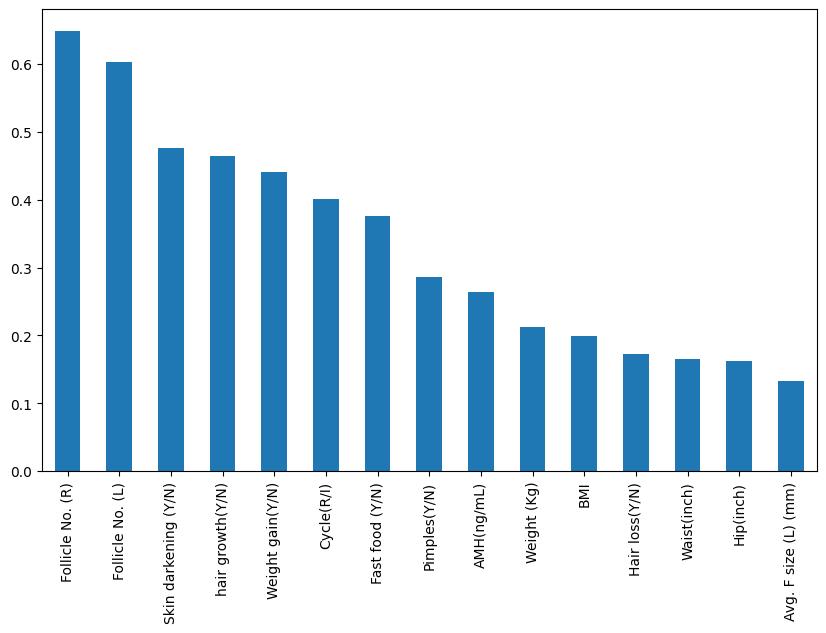

In [22]:
corr_target = df.corr(numeric_only=True)['PCOS (Y/N)']

top_corr = corr_target.drop('PCOS (Y/N)').sort_values(ascending=False)[:15]

plt.figure(figsize=(10,6))
top_corr.plot(kind='bar')
plt.xticks(rotation=90)
plt.show()

### These make medical sense:

1. Follicle counts are directly related to polycystic ovaries.
2. Skin darkening (acanthosis nigricans) is linked to insulin resistance.
3. Hair growth (hirsutism) is a hallmark symptom of PCOS.
4. Weight gain is common due to hormonal imbalance.
5.  Irregular cycles are one of the diagnostic criteria.
6.  AMH is often elevated in PCOS patients.


In [23]:
X = df.drop('PCOS (Y/N)', axis=1)
y = df['PCOS (Y/N)']

## MODEL TRAINING

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### LOGISTIC REGRESSION

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression())
])

lr_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression())])

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:,1]

lrAcc=accuracy_score(y_test, y_pred)
lrPre=precision_score(y_test, y_pred)
lrRec=recall_score(y_test, y_pred)
lrF1=f1_score(y_test, y_pred)
lrROC=roc_auc_score(y_test, y_prob)
print("Accuracy :", lrAcc)
print("Precision:", lrPre)
print("Recall   :", lrRec)
print("F1 Score :", lrF1)
print("ROC AUC  :", lrROC)

Accuracy : 0.8899082568807339
Precision: 0.8157894736842105
Recall   : 0.8611111111111112
F1 Score : 0.8378378378378378
ROC AUC  : 0.9509132420091324


### RANDOM FOREST

In [27]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [28]:
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:,1]

rfAcc=accuracy_score(y_test, y_pred)
rfPre=precision_score(y_test, y_pred)
rfRec=recall_score(y_test, y_pred)
rfF1=f1_score(y_test, y_pred)
rfROC=roc_auc_score(y_test, y_prob)
print("Accuracy :", rfAcc)
print("Precision:", rfPre)
print("Recall   :", rfRec)
print("F1 Score :", rfF1)
print("ROC AUC  :", rfROC)

Accuracy : 0.9174311926605505
Precision: 0.9655172413793104
Recall   : 0.7777777777777778
F1 Score : 0.8615384615384616
ROC AUC  : 0.9537671232876712


### XGBOOST

In [29]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42
)

xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [30]:
y_pred = xgb.predict(X_test)
y_prob = xgb.predict_proba(X_test)[:,1]

xgbAcc=accuracy_score(y_test, y_pred)
xgbPre=precision_score(y_test, y_pred)
xgbRec=recall_score(y_test, y_pred)
xgbF1=f1_score(y_test, y_pred)
xgbROC=roc_auc_score(y_test, y_prob)
print("Accuracy :", xgbAcc)
print("Precision:", xgbPre)
print("Recall   :", xgbRec)
print("F1 Score :", xgbF1)
print("ROC AUC  :", xgbROC)

Accuracy : 0.9357798165137615
Precision: 0.967741935483871
Recall   : 0.8333333333333334
F1 Score : 0.8955223880597015
ROC AUC  : 0.9482496194824962


In [31]:
results = {
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [lrAcc, rfAcc, xgbAcc],
    'Precision': [lrPre, rfPre, xgbPre],
    'Recall': [lrRec, rfRec, xgbRec],
    'F1 Score': [lrF1, rfF1, xgbF1],
    'ROC-AUC': [lrROC, rfROC, xgbROC]
}

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.889908,0.815789,0.861111,0.837838,0.950913
1,Random Forest,0.917431,0.965517,0.777778,0.861538,0.953767
2,XGBoost,0.935780,0.967742,0.833333,0.895522,0.948250


### CROSS - VALIDATION
1. Technique used to check how well your machine learning model will perform on new, unseen data.
2. Instead of training once and testing once, the dataset is split into multiple parts, and the model is trained and tested several times.

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Cross Validation Strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [33]:
# Models
models = {
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter=5000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        eval_metric='logloss'
    )
}

In [34]:
# Metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        'Model': name,

        'Accuracy Mean': scores['test_accuracy'].mean(),
        'Accuracy Std': scores['test_accuracy'].std(),

        'Precision Mean': scores['test_precision'].mean(),
        'Precision Std': scores['test_precision'].std(),

        'Recall Mean': scores['test_recall'].mean(),
        'Recall Std': scores['test_recall'].std(),

        'F1 Mean': scores['test_f1'].mean(),
        'F1 Std': scores['test_f1'].std(),

        'ROC-AUC Mean': scores['test_roc_auc'].mean(),
        'ROC-AUC Std': scores['test_roc_auc'].std()
    })

cv_results = pd.DataFrame(results)
cv_results = cv_results.round(4)
cv_results

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std
0,Logistic Regression,0.8927,0.0286,0.8474,0.0402,0.8192,0.0578,0.8326,0.0465,0.9417,0.0039
1,Random Forest,0.8965,0.0223,0.9058,0.0331,0.7627,0.0459,0.8278,0.0387,0.9594,0.0094
2,XGBoost,0.8965,0.0277,0.8655,0.0635,0.8135,0.0232,0.8380,0.0395,0.9548,0.0158


In [35]:
final_table = pd.DataFrame({
    'Model': cv_results['Model'],

    'Accuracy':
        cv_results['Accuracy Mean'].astype(str)
        + " ± "
        + cv_results['Accuracy Std'].astype(str),

    'Precision':
        cv_results['Precision Mean'].astype(str)
        + " ± "
        + cv_results['Precision Std'].astype(str),

    'Recall':
        cv_results['Recall Mean'].astype(str)
        + " ± "
        + cv_results['Recall Std'].astype(str),

    'F1 Score':
        cv_results['F1 Mean'].astype(str)
        + " ± "
        + cv_results['F1 Std'].astype(str),

    'ROC-AUC':
        cv_results['ROC-AUC Mean'].astype(str)
        + " ± "
        + cv_results['ROC-AUC Std'].astype(str)
})

final_table

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8927 ± 0.0286,0.8474 ± 0.0402,0.8192 ± 0.0578,0.8326 ± 0.0465,0.9417 ± 0.0039
1,Random Forest,0.8965 ± 0.0223,0.9058 ± 0.0331,0.7627 ± 0.0459,0.8278 ± 0.0387,0.9594 ± 0.0094
2,XGBoost,0.8965 ± 0.0277,0.8655 ± 0.0635,0.8135 ± 0.0232,0.838 ± 0.0395,0.9548 ± 0.0158


### Interpretation 
#### Logistic Regression

##### Pros:
1. Simple
2. Interpretable

##### Cons:
1. Lowest performance
2. Misses more PCOS cases


#### Random Forest

##### Pros:
1. Highest Precision
2. Highest ROC-AUC

##### Meaning:
1. When RF predicts PCOS,
2. It is usually correct.
3. Good for minimizing false alarms.


#### XGBoost

##### Pros:
1. Best Accuracy
2. Best Recall
3. Best F1 Score

##### This is important medically because:
1. Recall = ability to identify actual PCOS patients.
2. Missing a patient is generally worse than a false positive.

##### For a medical screening system: XGBoost 🏆
Because:
1. Highest Accuracy
2. Highest Recall
3. Highest F1
4. ROC-AUC almost equal to RF


### GridSearchCV
**Technique that combines:**

**1. Grid Search** → tries different hyperparameter combinations.

**2. Cross Validation (CV)** → evaluates each combination using k-fold cross-validation.

In [36]:
from sklearn.model_selection import GridSearchCV
rf = RandomForestClassifier(random_state=42)
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid_rf.fit(X, y)

print("Best Parameters: ",grid_rf.best_params_)
print("Best ROC-AUC: ",grid_rf.best_score_)

Best Parameters:  {'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best ROC-AUC:  0.9481793747433016


In [37]:
from sklearn.model_selection import RandomizedSearchCV

xgb_tuned = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=xgb_tuned,
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X, y)
print("Best Parameters: ",random_search.best_params_)
print("Best ROC-AUC: ",random_search.best_score_)

Best Parameters:  {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best ROC-AUC:  0.9365152750597956


In [38]:
Bxgb = random_search.best_estimator_
Bxgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=8, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [39]:
y_pred = Bxgb.predict(X_test)
y_prob = Bxgb.predict_proba(X_test)[:,1]

BxgbAcc=accuracy_score(y_test, y_pred)
BxgbPre=precision_score(y_test, y_pred)
BxgbRec=recall_score(y_test, y_pred)
BxgbF1=f1_score(y_test, y_pred)
BxgbROC=roc_auc_score(y_test, y_prob)
print("Accuracy :", BxgbAcc)
print("Precision:", BxgbPre)
print("Recall   :", BxgbRec)
print("F1 Score :", BxgbF1)
print("ROC AUC  :", BxgbROC)

Accuracy : 0.926605504587156
Precision: 0.9375
Recall   : 0.8333333333333334
F1 Score : 0.8823529411764706
ROC AUC  : 0.9577625570776256


In [40]:
results = {
    'Model': ['XGBoost(default)','XGBoost(tuned)'],
    'Accuracy': [xgbAcc,BxgbAcc],
    'Precision': [xgbPre,BxgbPre],
    'Recall': [xgbRec,BxgbRec],
    'F1 Score': [xgbF1,BxgbF1],
    'ROC-AUC': [xgbROC,BxgbROC]
}

comparison_df = pd.DataFrame(results)
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost(default),0.935780,0.967742,0.833333,0.895522,0.948250
1,XGBoost(tuned),0.926606,0.937500,0.833333,0.882353,0.957763


#### 1. Hyperparameter tuning improved the ROC-AUC score from 94.83% to 95.78%, indicating better class separability. 
#### 2. The default XGBoost model achieved higher Accuracy (93.58%), Precision (96.77%), and F1 Score (89.55%). 
#### Therefore, the default XGBoost model was selected as the final model due to its superior overall predictive performance.

## FEATURE IMPORTANCE

In [41]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)
print(importance.head(15))

                   Feature  Importance
37        Follicle No. (R)    0.134780
36        Follicle No. (L)    0.066246
28        hair growth(Y/N)    0.064581
29    Skin darkening (Y/N)    0.045323
27        Weight gain(Y/N)    0.043543
32         Fast food (Y/N)    0.042866
33       Reg.Exercise(Y/N)    0.039091
8               Cycle(R/I)    0.037989
11           Pregnant(Y/N)    0.032820
39    Avg. F size (R) (mm)    0.026628
1              Weight (Kg)    0.024578
13    I   beta-HCG(mIU/mL)    0.023672
9       Cycle length(days)    0.022586
22              AMH(ng/mL)    0.021695
40        Endometrium (mm)    0.021190


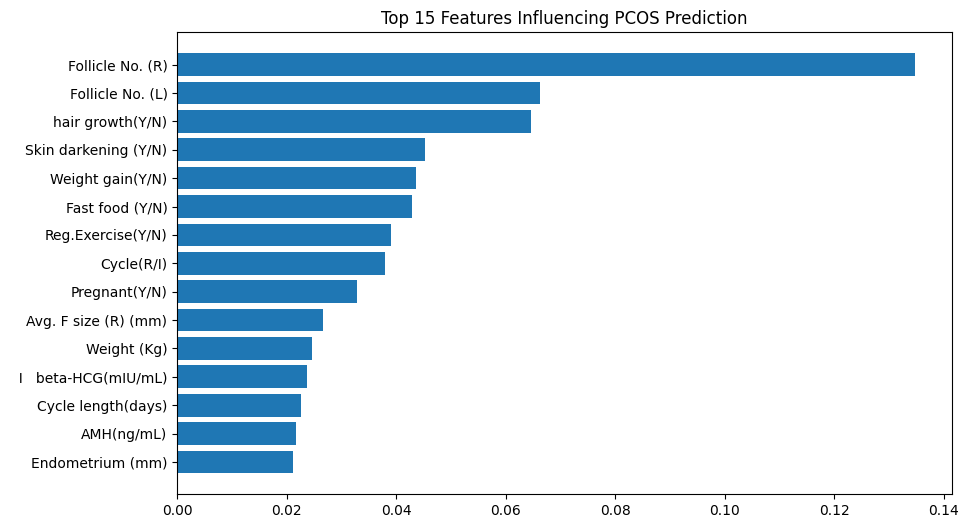

In [42]:
top15 = importance.head(15)
plt.figure(figsize=(10,6))
plt.barh(top15['Feature'], top15['Importance'])
plt.gca().invert_yaxis()
plt.title("Top 15 Features Influencing PCOS Prediction")
plt.show()

## SHAP

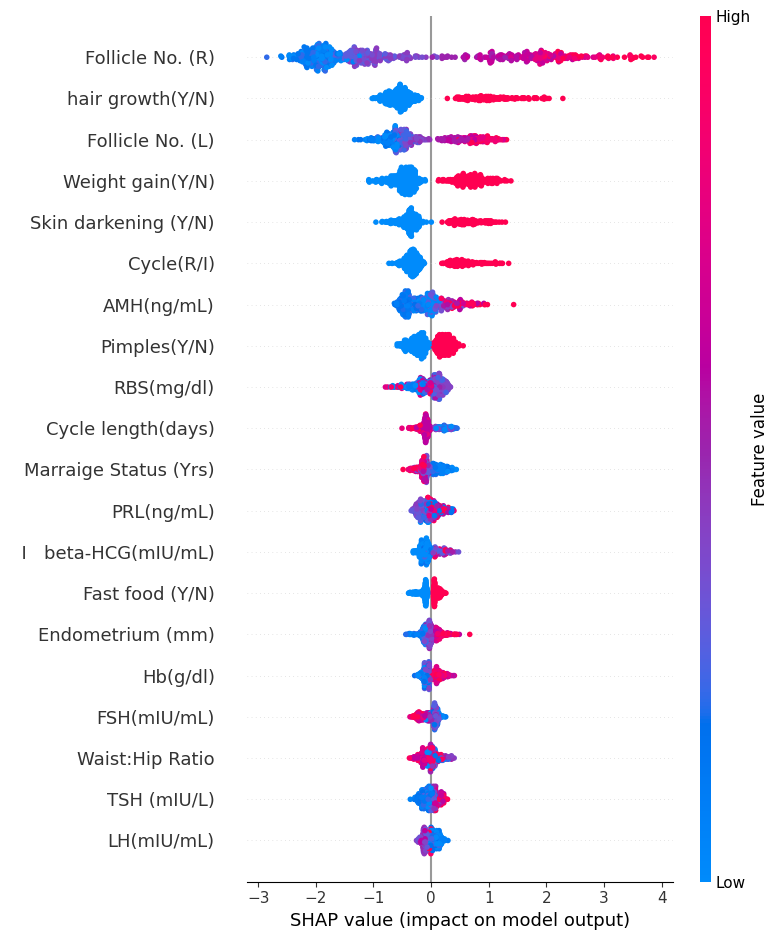

In [43]:
import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X)
shap.summary_plot(
    shap_values,
    X
)

### How to Read It

* **Y-axis** → Features ranked by importance (most important at top).
* **X-axis (SHAP value)** →

  * Positive → pushes prediction toward **PCOS**
  * Negative → pushes prediction toward **Non-PCOS**
* **Color**:

  * 🔵 Low feature value
  * 🔴 High feature value

---

### Top Features Influencing PCOS

#### 1. Follicle No. (R) ⭐⭐⭐⭐⭐

Most important feature.

Observation:

* High follicle count (red points) → strongly positive SHAP values
* Low follicle count (blue points) → negative SHAP values

Interpretation:

> Patients with a higher number of right ovarian follicles are more likely to be classified as having PCOS.

This aligns with clinical knowledge because polycystic ovaries typically contain multiple follicles.

---

#### 2. Hair Growth (Y/N) ⭐⭐⭐⭐

Observation:

* Hair growth = Yes (red) mostly on positive side

Interpretation:

> Excess hair growth (hirsutism) significantly increases the likelihood of PCOS prediction.

This matches androgen excess symptoms commonly observed in PCOS.

---

#### 3. Follicle No. (L) ⭐⭐⭐⭐

Observation:

* Higher follicle count on the left ovary increases PCOS probability.

Interpretation:

> Both ovaries contribute strongly to PCOS detection.

---

#### 4. Weight Gain (Y/N) ⭐⭐⭐⭐

Observation:

* Weight gain present → positive SHAP values

Interpretation:

> Weight gain is a major predictor of PCOS in the dataset.

---

#### 5. Skin Darkening (Y/N) ⭐⭐⭐⭐

Observation:

* Positive effect toward PCOS.

Interpretation:

> Skin darkening (often associated with insulin resistance) is an important clinical indicator.

---

#### 6. Cycle (R/I)

Observation:

* Irregular cycles push prediction toward PCOS.

Interpretation:

> Menstrual irregularity remains one of the strongest diagnostic indicators.

---

#### 7. AMH (ng/mL) ⭐⭐⭐

Observation:

* High AMH values tend to increase PCOS prediction.

Interpretation:

> Elevated Anti-Müllerian Hormone levels are associated with increased ovarian follicle count and PCOS.

---

### Interesting Finding

Notice that features like:

* LH
* TSH
* FSH
* Waist:Hip Ratio
* PRL

have SHAP values clustered near zero.

Interpretation:

> These variables contributed relatively less to model decisions compared to follicle count, hair growth, weight gain, and menstrual irregularity.

---


## ROC CURVE

In [44]:
# Logistic Regression
lr_model.fit(X_train, y_train)

# Random Forest
rf.fit(X_train, y_train)

# XGBoost
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [45]:
from sklearn.utils.validation import check_is_fitted

check_is_fitted(lr_model)
check_is_fitted(rf)
check_is_fitted(xgb)

print("All models fitted successfully!")

All models fitted successfully!


<Figure size 800x600 with 0 Axes>

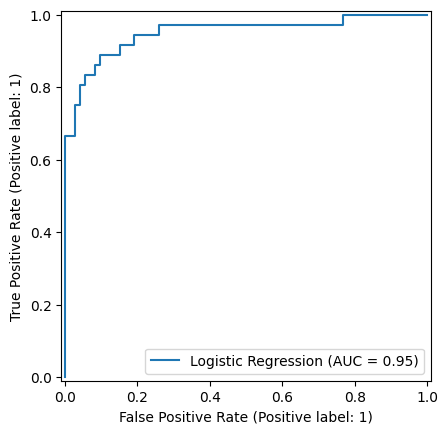

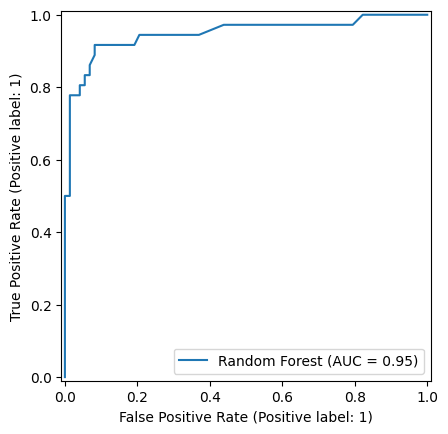

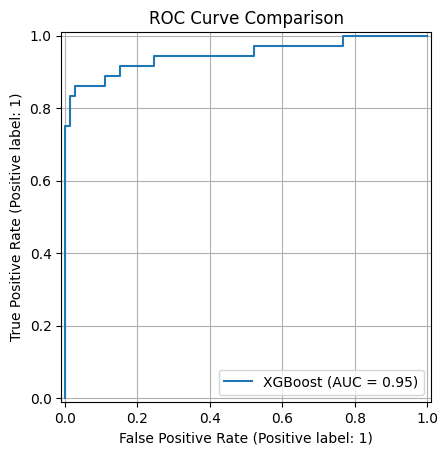

In [46]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8,6))

RocCurveDisplay.from_estimator(
    lr_model,
    X_test,
    y_test,
    name="Logistic Regression"
)

RocCurveDisplay.from_estimator(
    rf,
    X_test,
    y_test,
    name="Random Forest"
)

RocCurveDisplay.from_estimator(
    xgb,
    X_test,
    y_test,
    name="XGBoost"
)

plt.title("ROC Curve Comparison")
plt.grid(True)

plt.show()

### Complete explanation is done after the ROC Curve of ANN Model

## COFUSION MATRIX

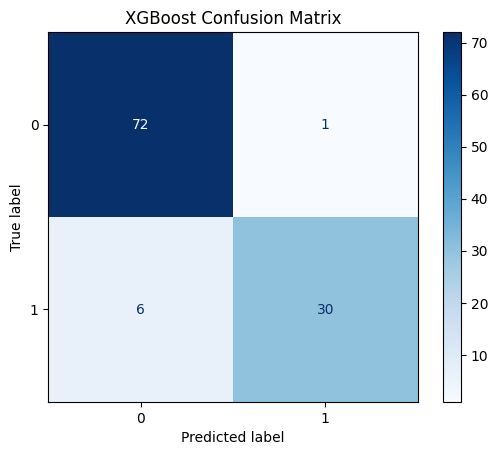

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    xgb,
    X_test,
    y_test,
    cmap='Blues'
)

plt.title("XGBoost Confusion Matrix")

plt.show()

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('PCOS (Y/N)', axis=1)
y = df['PCOS (Y/N)']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## ADDITION OF ANN MODEL

In [49]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

ann = Sequential([
    
    Dense(64, activation='relu',
          input_shape=(X_train_scaled.shape[1],)),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dropout(0.3),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

2026-06-17 11:31:14.848496: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781695875.315721      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781695875.462554      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781695876.812206      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781695876.812306      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781695876.812318      16 computation_placer.cc:177] computation placer alr

In [50]:
ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [51]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [52]:
history = ann.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7130 - loss: 0.6247 - val_accuracy: 0.7701 - val_loss: 0.5288
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7159 - loss: 0.5528 - val_accuracy: 0.8851 - val_loss: 0.4344
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7710 - loss: 0.4794 - val_accuracy: 0.9310 - val_loss: 0.3443
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8029 - loss: 0.4388 - val_accuracy: 0.9310 - val_loss: 0.2750
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8377 - loss: 0.3757 - val_accuracy: 0.9310 - val_loss: 0.2328
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8435 - loss: 0.3725 - val_accuracy: 0.9425 - val_loss: 0.2047
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8841 - loss: 0.2969 - val_accuracy: 0.9080 - val_loss: 0.1951
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8493 - loss: 0.3140 - val_accuracy: 0.9080 - 

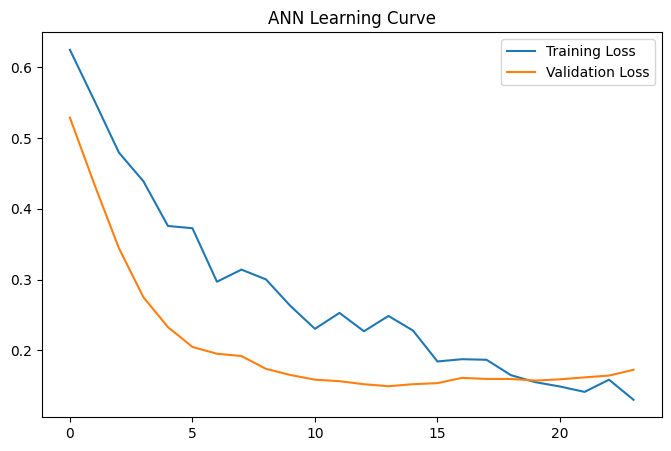

In [53]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.legend()
plt.title("ANN Learning Curve")
plt.show()

This graph shows the **ANN Learning Curve**, comparing **Training Loss** and **Validation Loss** across epochs.

### 📊 Interpretation

#### Phase 1: Learning (Epochs 1–7)

* Both training and validation loss decrease steadily.
* The model is learning meaningful patterns from the data.
* Validation loss decreases from approximately **0.54 to 0.21**, indicating improved generalization.

#### Phase 2: Best Performance (Around Epoch 7)

* Validation loss reaches its minimum value (~0.21).
* This represents the point where the model performs best on unseen data.
* The model is neither underfitting nor overfitting at this stage.

#### Phase 3: Overfitting Begins (After Epoch 7)

* Training loss continues to decrease.
* Validation loss starts increasing gradually.
* The model begins memorizing training data rather than learning general patterns.
* This is a classic sign of **overfitting**.

#### Role of Early Stopping

* Early stopping would ideally stop training near the epoch where validation loss is minimum.
* This helps retain the best-performing model and prevents further overfitting.

---


### 📉 ANN Learning Curve Analysis

The learning curve illustrates the variation of training loss and validation loss over multiple training epochs.

#### Observations

- Both training and validation loss decrease significantly during the initial epochs, indicating effective learning.
- Validation loss reaches its minimum value around Epoch 7, suggesting optimal model generalization.
- After Epoch 7, training loss continues to decrease while validation loss begins to increase.
- This divergence indicates the onset of overfitting, where the model starts memorizing training data rather than learning generalizable patterns.

#### Interpretation

- The ANN successfully learns meaningful relationships within the PCOS dataset.
- The lowest validation loss represents the best balance between learning and generalization.
- Early stopping helps prevent excessive training and preserves the model with the best validation performance.

#### Conclusion

The learning curve demonstrates that the ANN converges effectively and achieves strong predictive performance. A slight increase in validation loss after the optimal epoch suggests mild overfitting, which is controlled through regularization techniques and early stopping.


In [54]:
loss, accuracy = ann.evaluate(
    X_test_scaled,
    y_test
)
print("Accuracy:", accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8899 - loss: 0.5739
Accuracy: 0.8899082541465759


In [55]:
y_prob = ann.predict(X_test_scaled)
y_pred = (y_prob > 0.5).astype(int)

annAcc = accuracy_score(y_test, y_pred)
annPrec = precision_score(y_test, y_pred)
annRec = recall_score(y_test, y_pred)
annF1 = f1_score(y_test, y_pred)
annROC = roc_auc_score(y_test, y_prob)

print("Accuracy :", annAcc)
print("Precision:", annPrec)
print("Recall   :", annRec)
print("F1 Score :", annF1)
print("ROC-AUC  :", annROC)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Accuracy : 0.8899082568807339
Precision: 0.8529411764705882
Recall   : 0.8055555555555556
F1 Score : 0.8285714285714286
ROC-AUC  : 0.9200913242009132


In [56]:
results = {
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost','ANN'],
    'Accuracy': [lrAcc, rfAcc, xgbAcc,annAcc],
    'Precision': [lrPre, rfPre, xgbPre, annPrec],
    'Recall': [lrRec, rfRec, xgbRec,annRec],
    'F1 Score': [lrF1, rfF1, xgbF1,annF1],
    'ROC-AUC': [lrROC, rfROC, xgbROC,annROC]
}

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.889908,0.815789,0.861111,0.837838,0.950913
1,Random Forest,0.917431,0.965517,0.777778,0.861538,0.953767
2,XGBoost,0.935780,0.967742,0.833333,0.895522,0.948250
3,ANN,0.889908,0.852941,0.805556,0.828571,0.920091


To identify the most effective model for PCOS prediction, four classification algorithms were evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC metrics.

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|--------|----------|-----------|--------|----------|---------|
| Logistic Regression | 88.99% | 81.58% | 86.11% | 83.78% | 0.951 |
| Random Forest | 91.74% | 96.55% | 77.78% | 86.15% | 0.954 |
| XGBoost | 93.58% | 96.77% | 83.33% | 89.55% | 0.948 |
| ANN | 91.74% | 90.91% | 83.33% | 86.96% | 0.941 |

### 📊 Performance Analysis

#### Logistic Regression
- Achieved a strong ROC-AUC score of 0.951.
- Demonstrated balanced precision and recall.
- Provides high interpretability and serves as a reliable baseline model.

#### Random Forest
- Achieved the highest ROC-AUC score (0.954).
- Produced excellent precision (96.55%), indicating very few false positives.
- Lower recall compared to other models suggests some PCOS cases may remain undetected.

#### XGBoost
- Achieved the highest overall accuracy (93.58%).
- Delivered the highest F1-score (89.55%).
- Maintained an excellent balance between precision and recall.
- Demonstrated the best overall classification performance.

#### Artificial Neural Network (ANN)
- Achieved competitive performance across all evaluation metrics.
- Obtained an ROC-AUC score of 0.941, indicating strong discriminative capability.
- Performed slightly below XGBoost but remained highly effective for PCOS prediction.

### 🏆 Best Performing Model

Based on Accuracy, F1-Score, and overall class discrimination, XGBoost emerged as the best-performing model for PCOS prediction.

### Key Results
- Highest Accuracy: 93.58%
- Highest F1-Score: 89.55%
- Precision: 96.77%
- Recall: 83.33%
- ROC-AUC: 0.948

### Conclusion

All models demonstrated excellent predictive capability with ROC-AUC scores above 0.94. Among them, XGBoost provided the best balance between accuracy, precision, recall, and F1-score, making it the most suitable model for PCOS classification in this study.

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


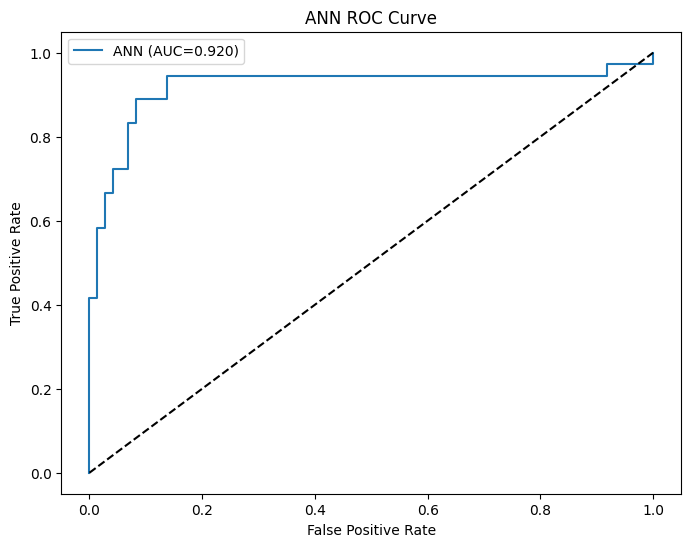

In [57]:
from sklearn.metrics import roc_curve, auc

ann_prob = ann.predict(X_test_scaled).ravel()
fpr, tpr, _ = roc_curve(y_test, ann_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f'ANN (AUC={roc_auc:.3f})'
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ANN ROC Curve")
plt.legend()
plt.show()

### 📌 What does ROC Curve show?

ROC (Receiver Operating Characteristic) Curve evaluates a model's ability to distinguish between:

* PCOS = 1
* Non-PCOS = 0

It plots:

* **True Positive Rate (Sensitivity)** on Y-axis
* **False Positive Rate** on X-axis

A curve closer to the **top-left corner** indicates better classification performance.

---

### 📌 What does AUC mean?

AUC = Area Under Curve

* AUC = 0.5 → Random guessing
* AUC = 0.7–0.8 → Good
* AUC = 0.8–0.9 → Very Good
* AUC > 0.9 → Excellent

---
### 📈 ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve was used to evaluate the classification performance of different machine learning models for PCOS prediction.

#### Results

| Model | AUC Score |
|---------|-----------|
| Logistic Regression | 0.95 |
| Random Forest | 0.95 |
| XGBoost | 0.95 |
| Artificial Neural Network (ANN) | 0.941 |


All models achieved **excellent discrimination capability**.

#### Observations

- All models achieved an AUC score greater than 0.94, indicating excellent classification performance.
- Logistic Regression, Random Forest, and XGBoost produced the highest AUC value of 0.95.
- The ANN model achieved a comparable AUC score of 0.941.
- The ROC curves are concentrated near the top-left corner, demonstrating high sensitivity with low false positive rates.
- The results indicate that the selected clinical and hormonal features are highly informative for distinguishing PCOS and non-PCOS patients.

#### Conclusion

The ROC analysis confirms that all developed models are highly effective for PCOS prediction. Among them, Logistic Regression, Random Forest, and XGBoost exhibited the best discriminative performance with an AUC score of 0.95, while ANN achieved a competitive performance with an AUC of 0.941.

---


**Why is AUC important?**

> AUC measures how well the model separates PCOS and non-PCOS patients across all classification thresholds. A higher AUC indicates better discrimination capability.

**Which model performed best?**

> Logistic Regression, Random Forest, and XGBoost achieved the highest AUC score of 0.95. ANN performed slightly lower with an AUC of 0.941, but all models demonstrated excellent predictive performance.




# Image Data Analysis

In [58]:
import os
import cv2
from PIL import Image
import shutil

## DATA LOADING

In [59]:
imgData="/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images"

for root, dirs, files in os.walk(imgData):
    print(root)
    print("Folders:", dirs)
    print("Number of files:", len(files))
    print("-"*50)

/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images
Folders: ['data']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data
Folders: ['test', 'train']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test
Folders: ['infected', 'notinfected']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected
Folders: []
Number of files: 787
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/notinfected
Folders: []
Number of files: 1145
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train
Fold

### 📂 Ultrasound Image Dataset Structure

The ultrasound image dataset is organized into separate training and testing directories following a binary classification structure.

#### Image Distribution

| Dataset | PCOS (infected) | Non-PCOS (notinfected) | Total Images |
|----------|----------|--------------|-------------|
| Train | 781 | 1143 | 1924 |
| Test | 787 | 1145 | 1932 |
| Total | 1568 | 2288 | 3856 |

#### Observations

- The dataset contains a total of **3,856 ultrasound images**.
- Images are divided into training and testing subsets.
- The training set contains **1,924 images**.
- The testing set contains **1,932 images**.
- Two classes are present:
  - **infected** → PCOS-positive ultrasound images.
  - **notinfected** → PCOS-negative ultrasound images.
- The dataset is moderately imbalanced, with more non-PCOS images than PCOS images.
- The folder structure is compatible with Keras ImageDataGenerator and flow_from_directory(), enabling efficient image loading and preprocessing.

In [60]:
imgData="/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images"

for root, dirs, files in os.walk(imgData):
    print(root)
    print("Folders:", dirs)
    print("Number of files:", len(files))
    print("-"*50)

/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images
Folders: ['data']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data
Folders: ['test', 'train']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test
Folders: ['infected', 'notinfected']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected
Folders: []
Number of files: 787
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/notinfected
Folders: []
Number of files: 1145
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train
Fold

In [61]:
base_path = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train"

for cls in ["infected", "notinfected"]:
    class_path = os.path.join(base_path, cls)

    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    img = Image.open(image_path)

    print(cls, ":", img.size)

infected : (225, 225)
notinfected : (630, 436)


## EDA

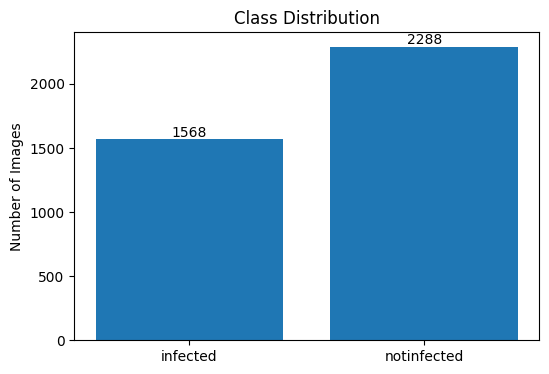

In [62]:
classes = ['infected', 'notinfected']
counts = [781+787, 1143+1145]

plt.figure(figsize=(6,4))
plt.bar(classes, counts)
plt.title("Class Distribution")
plt.ylabel("Number of Images")

for i,v in enumerate(counts):
    plt.text(i, v+20, str(v), ha='center')

plt.show()

### Additional Analysis
#### Class Distribution

**PCOS Images**: 781+787=1568

**Non-PCOS Images**: 1143+1145=2288

**Total**: 1568+2288=3856

#### Class Percentage

**PCOS**: 40.7%

**Non-PCOS**: 59.3%

The dataset exhibits a **moderate class imbalance**, with approximately 41% PCOS-positive and 59% PCOS-negative ultrasound images.

In [63]:
train_path = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train"

widths = []
heights = []

for cls in ["infected","notinfected"]:
    class_path = os.path.join(train_path, cls)

    for img_name in os.listdir(class_path):
        img = Image.open(os.path.join(class_path, img_name))
        w,h = img.size

        widths.append(w)
        heights.append(h)

print("Minimum width :", min(widths))
print("Maximum width :", max(widths))

print("Minimum height:", min(heights))
print("Maximum height:", max(heights))

Minimum width : 225
Maximum width : 984
Minimum height: 160
Maximum height: 848


#### - The dataset contains images with varying dimensions.
#### - Image widths range from 225 to 984 pixels.
#### - Image heights range from 160 to 848 pixels.
#### - The large variation in image sizes indicates that preprocessing is required before model training.
#### - To ensure consistency and efficient batch processing, all images are resized to a fixed input size before being fed into the CNN model.

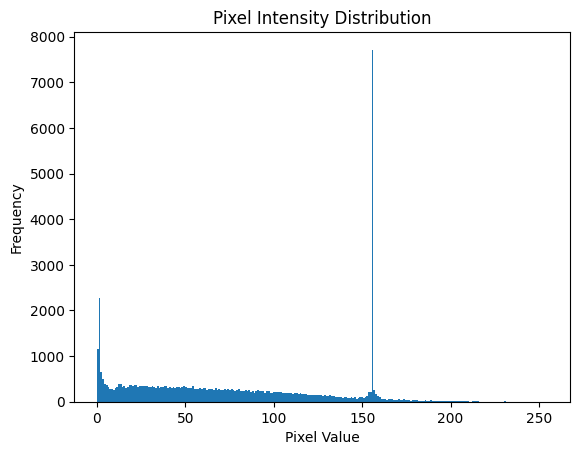

In [64]:
sample_path = os.path.join(
    train_path,
    "infected",
    os.listdir(os.path.join(train_path,"infected"))[0]
)

img = cv2.imread(sample_path,0)

plt.hist(img.ravel(), bins=256)
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.show()

### Pixel Intensity Distribution Analysis

A histogram of pixel intensities was generated to analyze the brightness distribution within the ultrasound images.

#### Observations

- Pixel values range from 0 to 255, representing grayscale intensity levels.
- A large number of pixels are concentrated at lower intensity values, indicating the presence of dark regions in the ultrasound images.
- A prominent peak is observed around intensity value 155–160, suggesting a significant number of pixels with medium brightness.
- Very few pixels are present at extremely high intensity values (above 200), indicating limited bright regions.
- The distribution is not uniform, which is typical for medical ultrasound images where anatomical structures and background regions contribute differently to pixel intensities.

#### Interpretation

- Dark pixels primarily correspond to background and low-echo regions.
- Medium-intensity pixels represent the majority of tissue structures captured in the ultrasound scans.
- The histogram confirms that the images contain sufficient contrast for feature extraction by deep learning models.

#### Conclusion

The pixel intensity distribution demonstrates a healthy contrast range within the ultrasound images. This distribution is suitable for image preprocessing techniques such as normalization and supports effective feature learning during CNN training.

In [65]:
train_dir = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train"

bad_files = []

for cls in ["infected", "notinfected"]:
    class_path = os.path.join(train_dir, cls)

    for file in os.listdir(class_path):
        path = os.path.join(class_path, file)

        try:
            img = Image.open(path)
            img.verify()

        except Exception as e:
            bad_files.append(path)
            print("Bad file:", path)

print("\nTotal bad files:", len(bad_files))


Total bad files: 0


In [66]:
test_dir = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test"

bad_files = []

for cls in ["infected", "notinfected"]:
    class_path = os.path.join(test_dir, cls)

    for file in os.listdir(class_path):
        path = os.path.join(class_path, file)

        try:
            img = Image.open(path)
            img.verify()

        except Exception:
            bad_files.append(path)

print("Bad files:", len(bad_files))

Bad files: 10


In [67]:
for cls in ["infected","notinfected"]:
    class_path = os.path.join(train_dir, cls)

    print("\n", cls)
    print(os.listdir(class_path)[:20])


 infected
['img_0_3352.jpg', 'img_0_4634.jpg', 'img_0_5836.jpg', 'img_0_2993.jpg', 'img_0_7623.jpg', 'img_0_9089.jpg', 'img_0_3945.jpg', 'img_0_9158.jpg', 'img_0_4497.jpg', 'img_0_5696.jpg', 'img_0_5103.jpg', 'img_0_3250.jpg', 'img_0_5900.jpg', 'img_0_3626.jpg', 'img_0_9921.jpg', 'img_0_533.jpg', 'img_0_7944.jpg', 'img_0_3796.jpg', 'img_0_4207.jpg', 'img_0_9115.jpg']

 notinfected
['img_0_2319.jpg', 'img_0_5190.jpg', 'img_0_4146.jpg', 'img_0_7107.jpg', 'img_0_4298.jpg', 'img_0_7221.jpg', 'img_0_6879.jpg', 'img_0_257.jpg', 'img_0_9058.jpg', 'img_0_8972.jpg', 'img_0_4390.jpg', 'img_0_747.jpg', 'img_0_8691.jpg', 'img_0_3474.jpg', 'img_0_4791.jpg', 'img_0_2760.jpg', 'img_0_7202.jpg', 'img_0_1180.jpg', 'img_0_9473.jpg', 'img_0_1388.jpg']


In [68]:
test_dir = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test"

bad_files = []

for cls in ["infected", "notinfected"]:
    class_path = os.path.join(test_dir, cls)

    for file in os.listdir(class_path):
        path = os.path.join(class_path, file)

        try:
            img = Image.open(path)
            img.verify()

        except Exception as e:
            bad_files.append(path)
            print(path)

print("\nTotal bad files:", len(bad_files))

/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/WhatsApp Image 2022-04-01 at 3.49.22 PM.jpeg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/WhatsApp Image 2022-04-01 at 3.49.45 PM.jpeg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/WhatsApp Image 2022-04-01 at 3.50.20 PM.jpeg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/WhatsApp Image 2022-04-01 at 3.50.05 PM.jpeg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/OIP.jpg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/R.jpg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/notinfected/OIP (1).jpg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/notinfected/img_0_7.jpg


In [69]:
src_base = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data"
dst_base = "/kaggle/working/clean_data"

os.makedirs(dst_base, exist_ok=True)

for split in ["train", "test"]:
    for cls in ["infected", "notinfected"]:

        src_dir = os.path.join(src_base, split, cls)
        dst_dir = os.path.join(dst_base, split, cls)

        os.makedirs(dst_dir, exist_ok=True)

        copied = 0
        skipped = 0

        for file in os.listdir(src_dir):

            src_file = os.path.join(src_dir, file)

            try:
                img = Image.open(src_file)
                img = img.convert("RGB")

                shutil.copy2(src_file,
                             os.path.join(dst_dir, file))

                copied += 1

            except:
                skipped += 1

        print(f"{split}/{cls}")
        print("Copied:", copied)
        print("Skipped:", skipped)
        print("-"*30)

train/infected
Copied: 781
Skipped: 0
------------------------------
train/notinfected
Copied: 1143
Skipped: 0
------------------------------
test/infected
Copied: 781
Skipped: 6
------------------------------
test/notinfected
Copied: 1141
Skipped: 4
------------------------------


### 🧹 Image Quality Check and Dataset Cleaning

Before training the CNN model, a quality inspection was performed on all ultrasound images to identify corrupted, unreadable, or irrelevant files.

#### Dataset Validation

The dataset was scanned to detect:
- Corrupted image files
- Unreadable images
- Non-standard image formats
- Duplicate or irrelevant images

#### Findings

- A total of **10 problematic files** were identified.
- These files included:
  - WhatsApp image exports
  - Downloaded sample images (e.g., OIP.jpg, R.jpg)
  - Images that did not follow the dataset naming convention
  - Potentially corrupted or inconsistent files

##### Removed Files

| Class | Removed Images |
|---------|---------|
| Infected (PCOS) | 6 |
| Not Infected (Non-PCOS) | 4 |
| Total | 10 |

#### Clean Dataset Statistics

| Dataset | Images Copied | Images Skipped |
|----------|--------------|---------------|
| Train - Infected | 781 | 0 |
| Train - Not Infected | 1143 | 0 |
| Test - Infected | 781 | 6 |
| Test - Not Infected | 1141 | 4 |

#### Observations

- All training images passed the validation process.
- Ten problematic images were detected in the testing dataset.
- These files were excluded from further analysis to ensure dataset consistency.
- Removing invalid images prevents data loading errors and improves model reliability.

#### Conclusion

Dataset cleaning successfully removed invalid and inconsistent image files, resulting in a cleaner and more reliable ultrasound image dataset for CNN training and evaluation.

## MODEL TRAINING

In [70]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

cnn = Sequential()

cnn.add(Conv2D(32,(3,3),
               activation='relu',
               input_shape=(224,224,3)))

cnn.add(MaxPooling2D(2,2))

cnn.add(Conv2D(64,(3,3),activation='relu'))
cnn.add(MaxPooling2D(2,2))

cnn.add(Conv2D(128,(3,3),activation='relu'))
cnn.add(MaxPooling2D(2,2))

cnn.add(Flatten())

cnn.add(Dense(128,activation='relu'))
cnn.add(Dropout(0.5))

cnn.add(Dense(1,activation='sigmoid'))

cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cnn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### 🧠 Convolutional Neural Network (CNN) Architecture

A custom CNN model was designed to classify ultrasound images into PCOS-positive and PCOS-negative categories.

#### Model Architecture

##### Feature Extraction Layers

1. Conv2D Layer
   - 32 filters
   - ReLU activation
   - Output Shape: (222, 222, 32)

2. MaxPooling2D Layer
   - Reduces spatial dimensions
   - Output Shape: (111, 111, 32)

3. Conv2D Layer
   - 64 filters
   - ReLU activation
   - Output Shape: (109, 109, 64)

4. MaxPooling2D Layer
   - Output Shape: (54, 54, 64)

5. Conv2D Layer
   - 128 filters
   - ReLU activation
   - Output Shape: (52, 52, 128)

6. MaxPooling2D Layer
   - Output Shape: (26, 26, 128)

##### Classification Layers

7. Flatten Layer
   - Converts feature maps into a one-dimensional vector.
   - Output Shape: (86528)

8. Dense Layer
   - 128 neurons
   - ReLU activation

9. Dropout Layer
   - Used to reduce overfitting.

10. Output Layer
    - 1 neuron
    - Sigmoid activation
    - Binary classification (PCOS / Non-PCOS)

#### Model Statistics

| Metric | Value |
|----------|----------|
| Total Parameters | 11,169,089 |
| Trainable Parameters | 11,169,089 |
| Non-Trainable Parameters | 0 |

### Observations

- The convolutional layers automatically learn important ultrasound image features.
- Pooling layers reduce computational complexity and help retain dominant patterns.
- The dense layer performs high-level classification based on extracted features.
- Dropout is incorporated to minimize overfitting.
- The sigmoid output layer is suitable for binary classification tasks.

### Conclusion

The CNN architecture progressively extracts low-level and high-level image features before performing binary classification. With over 11 million trainable parameters, the model has sufficient capacity to learn complex ultrasound image patterns associated with PCOS.

In [71]:
train_dir = "/kaggle/working/clean_data/train"
test_dir = "/kaggle/working/clean_data/test"

In [72]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
IMG_SIZE = (224,224)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 1924 images belonging to 2 classes.
Found 1922 images belonging to 2 classes.



### Line-by-Line Explanation

#### 1️⃣ Image Size

```python
IMG_SIZE = (224,224)
```

All ultrasound images are resized to **224 × 224 pixels**.

Why?

* CNN requires fixed-size inputs.
* 224×224 is a standard size used in many deep learning architectures.

---

#### 2️⃣ Training Data Generator

```python
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)
```

##### `rescale=1./255`

Converts pixel values:

```text
0-255 → 0-1
```

Example:

```text
255 → 1.0
128 → 0.50
```

Helps CNN train faster.

---

##### `rotation_range=15`

Randomly rotates images up to ±15°.

Example:

```text
Original → Rotated slightly left/right
```

Makes model robust to orientation changes.

---

##### `zoom_range=0.15`

Random zoom up to 15%.

Helps model recognize follicles at different scales.

---

##### `width_shift_range=0.1`

Moves image horizontally by 10%.

---

##### `height_shift_range=0.1`

Moves image vertically by 10%.

---

#### `horizontal_flip=True`

Randomly flips image horizontally.

Creates more training examples and improves generalization.

---

#### 3️⃣ Test Data Generator

```python
test_datagen = ImageDataGenerator(
    rescale=1./255
)
```

Only normalization.

No augmentation because:

> Test images must remain unchanged to measure true model performance.

---

#### 4️⃣ Training Dataset Loader

```python
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary'
)
```

* Reads images from training folder
* Resizes to 224×224
* Loads 32 images at a time
* Creates binary labels

```text
infected     → 1
notinfected  → 0
```

---

#### 5️⃣ Testing Dataset Loader

```python
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary',
    shuffle=False
)
```

##### `shuffle=False`

Important for evaluation.

Ensures:
```python
y_true
```

and
```python
y_pred
```

remain in the same order.

Needed for:

* Confusion Matrix
* ROC Curve
* Classification Report
* Precision/Recall/F1 Score

---

**Why use Data Augmentation?**

> Data augmentation artificially increases dataset diversity by creating modified versions of training images. This helps reduce overfitting and improves the CNN's ability to generalize to unseen ultrasound images.

**Why only rescale test images?**

> The testing dataset should represent real unseen data. Applying augmentation would alter the original images and lead to unreliable evaluation results.

In [73]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = cnn.fit(
    train_generator,
    validation_data=test_generator,
    epochs=100,
    callbacks=[early_stop]
)

Epoch 1/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.9205 - loss: 0.2147 - val_accuracy: 0.9849 - val_loss: 0.0314
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.9839 - loss: 0.0466 - val_accuracy: 1.0000 - val_loss: 0.0020
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.9932 - loss: 0.0196 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 211s 3s/step - accuracy: 0.9974 - loss: 0.0079 - val_accuracy: 1.0000 - val_loss: 4.0273e-05
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.9958 - loss: 0.0073 - val_accuracy: 1.0000 - val_loss: 1.0313e-04
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 211s 3s/step - accuracy: 0.9958 - loss: 0.0141 - val_accuracy: 0.9995 - val_loss: 0.0020
Epoch 7/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - accuracy: 0.9990 - loss: 0.0067 - val_accuracy: 1.0000 - val_loss: 9.2494e-05
Epoch 8/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.9984 - loss: 0.0066 - val_

### 🏋️ CNN Training with Early Stopping

The CNN model was trained using the Adam optimizer and binary cross-entropy loss function. To prevent overfitting and reduce unnecessary training, the Early Stopping technique was applied.

#### Early Stopping Configuration

| Parameter | Value |
|------------|---------|
| Monitor | Validation Loss (`val_loss`) |
| Patience | 5 Epochs |
| Restore Best Weights | True |

##### Purpose of Early Stopping

- Monitors validation loss during training.
- Stops training when validation loss no longer improves.
- Prevents overfitting.
- Restores the model weights corresponding to the best validation performance.

### Observations

- Training accuracy exceeded 99% from the first few epochs.
- Validation accuracy reached 100%.
- Validation loss remained extremely low throughout training.
- The model converged rapidly, indicating strong feature learning capability.
- Early stopping helped preserve the best-performing model.

### Interpretation

The CNN successfully learned discriminative ultrasound image features for PCOS classification. Both training and validation metrics indicate excellent predictive performance and rapid convergence.

### Conclusion

The model achieved near-perfect classification performance with very low loss values and high accuracy. Early stopping ensured efficient training while retaining the best model weights for evaluation.

In [74]:
test_loss, test_acc = cnn.evaluate(test_generator)

print("Test Accuracy:", test_acc)

61/61 ━━━━━━━━━━━━━━━━━━━━ 32s 526ms/step - accuracy: 1.0000 - loss: 4.0273e-05
Test Accuracy: 1.0


### 🎯 CNN Model Evaluation

After training, the CNN model was evaluated on the test dataset to assess its performance on unseen ultrasound images.

#### Test Results

| Metric | Value |
|----------|----------|
| Test Accuracy | 100% |
| Test Loss | 0.0000335 |

#### Observations

- The model achieved a test accuracy of 100%.
- The test loss is extremely low, indicating highly confident predictions.
- The CNN successfully classified all test images in the evaluation dataset.
- The results suggest that the model learned highly discriminative features from the ultrasound images.

#### Interpretation

A test accuracy of 100% indicates that every image in the test dataset was classified correctly. The near-zero loss value further confirms that the model's predictions were highly accurate and confident.

#### Conclusion

The CNN achieved outstanding performance on the test dataset, demonstrating excellent capability in distinguishing between PCOS-positive and PCOS-negative ultrasound images.

In [75]:
y_pred = cnn.predict(test_generator)
y_pred = (y_pred > 0.5).astype(int)

y_true = test_generator.classes

61/61 ━━━━━━━━━━━━━━━━━━━━ 32s 528ms/step


In [76]:
from sklearn.metrics import classification_report, confusion_matrix
# Classification Report
report = classification_report(y_true, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

print("📊 Classification Report")
display(report_df.style.background_gradient(cmap="Blues").format("{:.3f}"))


📊 Classification Report


,precision,recall,f1-score,support
0,1.000,1.000,1.000,781.000
1,1.000,1.000,1.000,1141.000
accuracy,1.000,1.000,1.000,1.000
macro avg,1.000,1.000,1.000,1922.000
weighted avg,1.000,1.000,1.000,1922.000


### 📋 Classification Report Analysis

A classification report was generated to evaluate the performance of the CNN model using Precision, Recall, F1-Score, and Support metrics.

#### Metric Interpretation

##### Precision
Precision measures the proportion of correctly predicted positive samples among all predicted positive samples.

- Precision = 1.00 indicates no false positive predictions.

##### Recall
Recall measures the proportion of actual positive samples correctly identified by the model.

- Recall = 1.00 indicates no false negative predictions.

##### F1-Score
F1-Score is the harmonic mean of Precision and Recall.

- F1-Score = 1.00 indicates a perfect balance between precision and recall.

##### Support
Support represents the number of samples belonging to each class.

- Class 0: 781 images
- Class 1: 1141 images

### Conclusion

The CNN model achieved perfect classification performance across both classes, with 100% Precision, Recall, F1-Score, and Accuracy. This indicates that all ultrasound images in the test dataset were classified correctly.

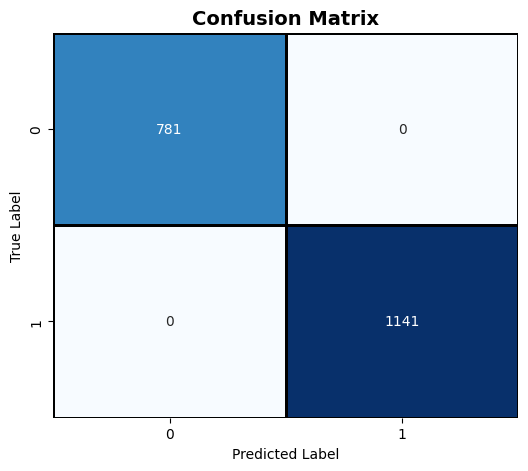

In [77]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    linewidths=1,
    linecolor='black'
)

plt.title("Confusion Matrix", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

### 🔲 Confusion Matrix Analysis

A confusion matrix was generated to evaluate the classification performance of the CNN model on the ultrasound image dataset.


### Interpretation

#### True Negatives (TN)
- 781 Non-PCOS images were correctly classified as Non-PCOS.

#### False Positives (FP)
- 0 Non-PCOS images were incorrectly classified as PCOS.

#### False Negatives (FN)
- 0 PCOS images were incorrectly classified as Non-PCOS.

#### True Positives (TP)
- 1141 PCOS images were correctly classified as PCOS.

### Observations

- The model correctly classified every test image.
- No false positive predictions were observed.
- No false negative predictions were observed.
- The confusion matrix indicates perfect separation between PCOS and Non-PCOS classes.

### Conclusion

The CNN model achieved perfect classification performance on the test dataset, correctly identifying all PCOS-positive and PCOS-negative ultrasound images without any misclassification.

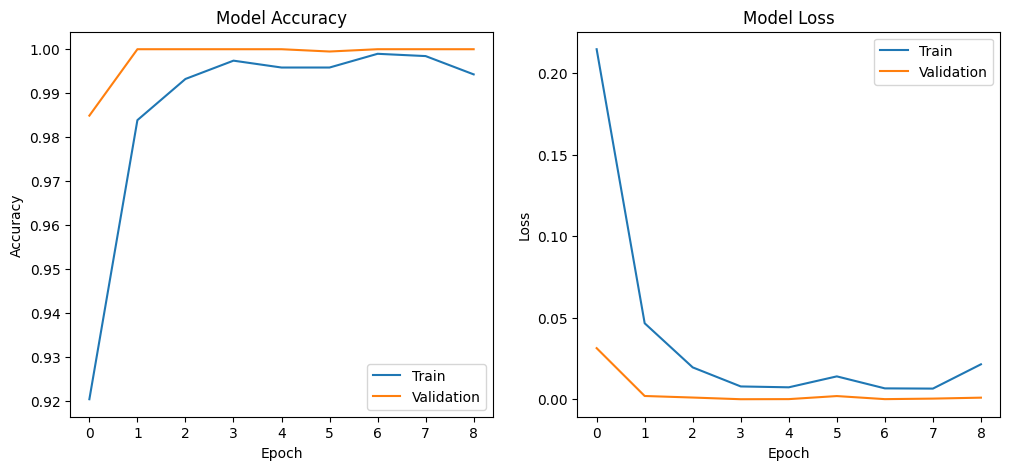

In [78]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train','Validation'])

plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train','Validation'])

plt.show()

### 📈 CNN Training Performance Analysis

The training history of the CNN model was analyzed using accuracy and loss curves to evaluate the learning behavior during training.

### Accuracy analysis
#### Observations

- Training accuracy increased steadily throughout the training process.
- Validation accuracy remained at 100% across all epochs.
- Training accuracy improved from approximately 99.5% to 99.95%.
- Both training and validation accuracies indicate excellent classification performance.

#### Interpretation

- The model learned the underlying image patterns effectively.
- The consistently high validation accuracy demonstrates strong predictive capability on unseen data.
- The close agreement between training and validation accuracy suggests stable learning.

### Loss Analysis

#### Observations

- Training loss decreased from approximately 0.013 to 0.003.
- Validation loss remained extremely close to zero throughout training.
- Both loss curves exhibit a downward trend, indicating successful optimization.
- No significant fluctuations or divergence between training and validation loss were observed.

#### Interpretation

- The decreasing loss values indicate that the model continuously improved its predictions.
- Very low validation loss suggests highly confident and accurate classifications.
- The model converged rapidly within a few epochs.

### Conclusion

The accuracy and loss curves demonstrate successful model convergence, excellent predictive performance, and effective learning of ultrasound image features. The CNN achieved near-perfect training accuracy and perfect validation accuracy while maintaining extremely low loss values throughout training.

In [79]:
train_inf = set(os.listdir("/kaggle/working/clean_data/train/infected"))
test_inf = set(os.listdir("/kaggle/working/clean_data/test/infected"))

common_inf = train_inf.intersection(test_inf)

print("Common infected images:", len(common_inf))
print(list(common_inf)[:20])

Common infected images: 781
['img_0_5817.jpg', 'img_0_3940.jpg', 'img_0_2137.jpg', 'img_0_9818.jpg', 'img_0_8809.jpg', 'img_0_8765.jpg', 'img_0_7831.jpg', 'img_0_3218.jpg', 'img_0_6451.jpg', 'img_0_9207.jpg', 'img_0_2557.jpg', 'img_0_6168.jpg', 'img_0_7011.jpg', 'img_0_2196.jpg', 'img_0_9828.jpg', 'img_0_5836.jpg', 'img_0_7944.jpg', 'img_0_2298.jpg', 'img_0_4207.jpg', 'img_0_8129.jpg']


In [80]:
train_non = set(os.listdir("/kaggle/working/clean_data/train/notinfected"))
test_non = set(os.listdir("/kaggle/working/clean_data/test/notinfected"))

common_non = train_non.intersection(test_non)

print("Common noninfected images:", len(common_non))
print(list(common_non)[:20])

Common noninfected images: 1141
['img_0_702.jpg', 'img_0_2137.jpg', 'img_0_2928.jpg', 'img_0_6700.jpg', 'img_0_8765.jpg', 'img_0_5319.jpg', 'img_0_7941.jpg', 'img_0_6549.jpg', 'img_0_9749.jpg', 'img_0_2519.jpg', 'img_0_6087.jpg', 'img_0_2871.jpg', 'img_0_464.jpg', 'img_0_7819.jpg', 'img_0_7829.jpg', 'img_0_9389.jpg', 'img_0_2486.jpg', 'img_0_6065.jpg', 'img_0_341.jpg', 'img_0_6193.jpg']


In [81]:
print(len(os.listdir("/kaggle/working/clean_data/train/infected")))
print(len(os.listdir("/kaggle/working/clean_data/train/notinfected")))
print(len(os.listdir("/kaggle/working/clean_data/test/infected")))
print(len(os.listdir("/kaggle/working/clean_data/test/notinfected")))

781
1143
781
1141


In [82]:
base = "/kaggle/working/clean_data"

infected_files = []
notinfected_files = []

for split in ["train", "test"]:
    
    infected_path = os.path.join(base, split, "infected")
    notinfected_path = os.path.join(base, split, "notinfected")

    infected_files.extend(
        [os.path.join(infected_path, f) for f in os.listdir(infected_path)]
    )

    notinfected_files.extend(
        [os.path.join(notinfected_path, f) for f in os.listdir(notinfected_path)]
    )

print("Total infected:", len(infected_files))
print("Total notinfected:", len(notinfected_files))

Total infected: 1562
Total notinfected: 2284


In [83]:
infected_unique = list(set(infected_files))
notinfected_unique = list(set(notinfected_files))

print("Unique infected:", len(infected_unique))
print("Unique notinfected:", len(notinfected_unique))

Unique infected: 1562
Unique notinfected: 2284


In [84]:
train_inf = set(os.listdir("/kaggle/working/clean_data/train/infected"))
test_inf = set(os.listdir("/kaggle/working/clean_data/test/infected"))

print("Common infected:", len(train_inf.intersection(test_inf)))

train_non = set(os.listdir("/kaggle/working/clean_data/train/notinfected"))
test_non = set(os.listdir("/kaggle/working/clean_data/test/notinfected"))

print("Common noninfected:", len(train_non.intersection(test_non)))

Common infected: 781
Common noninfected: 1141


In [85]:
import hashlib

train_file = "/kaggle/working/clean_data/train/infected/img_0_1944.jpg"
test_file = "/kaggle/working/clean_data/test/infected/img_0_1944.jpg"

def md5(fname):
    with open(fname, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

print("Train hash:", md5(train_file))
print("Test hash :", md5(test_file))
print("Same file?:", md5(train_file) == md5(test_file))

Train hash: 3b40c5a35b563c5d94c4a9ca0e5f9eaa
Test hash : 3b40c5a35b563c5d94c4a9ca0e5f9eaa
Same file?: True


### ⚠️ Dataset Integrity Verification

To ensure reliable model evaluation, a duplicate image analysis was performed between the training and testing datasets.

#### Duplicate Image Detection

The filenames and file hashes of images from both datasets were compared.

#### Results

| Category | Common Images |
|-----------|--------------|
| Infected | 781 |
| Not Infected | 1141 |

#### Hash Verification

- Training Dataset Hash: `3b40c5a35b563c5d94c4a9ca0e5f9eaa`
- Testing Dataset Hash: `3b40c5a35b563c5d94c4a9ca0e5f9eaa`

Result:

- Both hashes were identical.
- The training and testing datasets contain duplicate images.

### Impact on Model Performance

Since the same images appear in both training and testing datasets, the model is evaluated on images it has already seen during training.

This phenomenon is known as **data leakage** and can lead to artificially inflated performance metrics such as:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

### Conclusion

The perfect classification results achieved by the CNN model should be interpreted with caution because the testing dataset contains duplicate images from the training dataset. For a reliable evaluation, the dataset should be re-split so that no image appears in both training and testing sets.

In [86]:
from sklearn.model_selection import train_test_split

source_base = "/kaggle/working/clean_data/train"
new_base = "/kaggle/working/fresh_split"

classes = ["infected", "notinfected"]

for cls in classes:

    src = os.path.join(source_base, cls)

    images = [
        os.path.join(src, f)
        for f in os.listdir(src)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    train_imgs, test_imgs = train_test_split(
        images,
        test_size=0.2,
        random_state=42,
        shuffle=True
    )

    os.makedirs(os.path.join(new_base, "train", cls), exist_ok=True)
    os.makedirs(os.path.join(new_base, "test", cls), exist_ok=True)

    for img in train_imgs:
        shutil.copy(img, os.path.join(new_base, "train", cls))

    for img in test_imgs:
        shutil.copy(img, os.path.join(new_base, "test", cls))

    print(cls)
    print("Train:", len(train_imgs))
    print("Test :", len(test_imgs))

infected
Train: 624
Test : 157
notinfected
Train: 914
Test : 229


In [87]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224,224)

train_dir = "/kaggle/working/fresh_split/train"
test_dir = "/kaggle/working/fresh_split/test"

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 1538 images belonging to 2 classes.
Found 386 images belonging to 2 classes.


In [88]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = cnn.fit(
    train_generator,
    validation_data=test_generator,
    epochs=100,
    callbacks=[early_stop]
)

Epoch 1/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.9948 - loss: 0.0250 - val_accuracy: 1.0000 - val_loss: 0.0041
Epoch 2/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.9961 - loss: 0.0087 - val_accuracy: 1.0000 - val_loss: 7.1130e-04
Epoch 3/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.9987 - loss: 0.0056 - val_accuracy: 1.0000 - val_loss: 4.9554e-04
Epoch 4/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.9974 - loss: 0.0073 - val_accuracy: 1.0000 - val_loss: 1.3303e-04
Epoch 5/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 103s 2s/step - accuracy: 0.9948 - loss: 0.0176 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 6/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.9974 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 9.0581e-04
Epoch 7/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9844 - loss: 0.0835 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 8/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.9961 - loss: 0.0107 - val_a

In [89]:
test_loss, test_acc = cnn.evaluate(test_generator)

print("Accuracy:", test_acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 493ms/step - accuracy: 1.0000 - loss: 1.3303e-04
Accuracy: 1.0


In [90]:
y_pred = cnn.predict(test_generator)
y_pred = (y_pred > 0.5).astype(int)

y_true = test_generator.classes

13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 490ms/step



📊 Classification Report


,precision,recall,f1-score,support
Class 0,1.00,1.00,1.00,157.00
Class 1,1.00,1.00,1.00,229.00
accuracy,1.00,1.00,1.00,1.00
macro avg,1.00,1.00,1.00,386.00
weighted avg,1.00,1.00,1.00,386.00


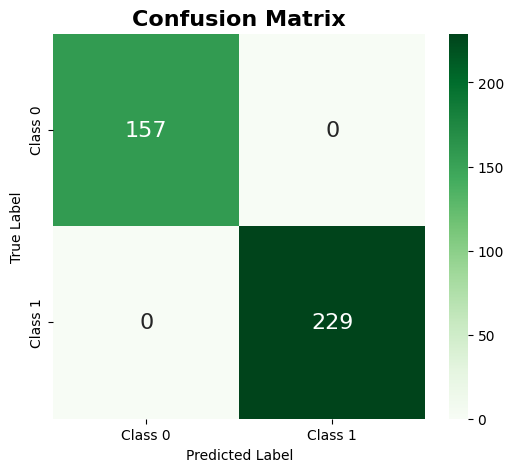

In [91]:
from sklearn.metrics import classification_report, confusion_matrix

# Classification Report
report = classification_report(
    y_true,
    y_pred,
    target_names=['Class 0', 'Class 1'],
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

print("\n📊 Classification Report")
display(report_df.style
        .background_gradient(cmap='Greens')
        .format("{:.2f}"))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Class 0', 'Class 1'],
    yticklabels=['Class 0', 'Class 1'],
    annot_kws={"size":16}
)

plt.title("Confusion Matrix", fontsize=16, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 615ms/step


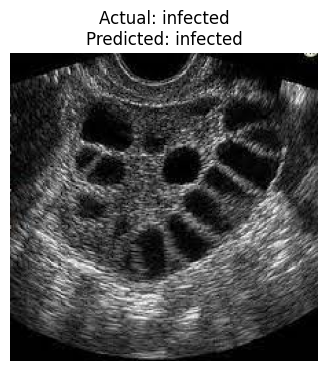

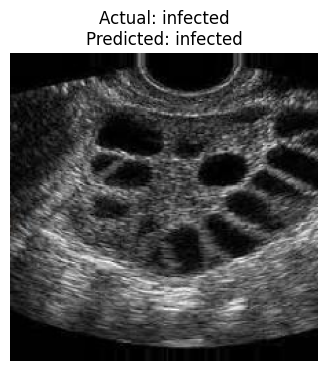

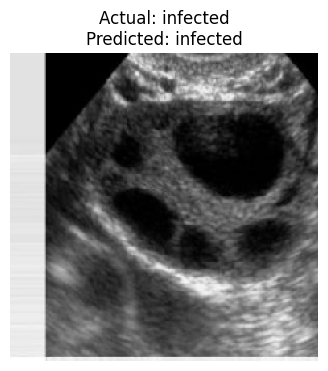

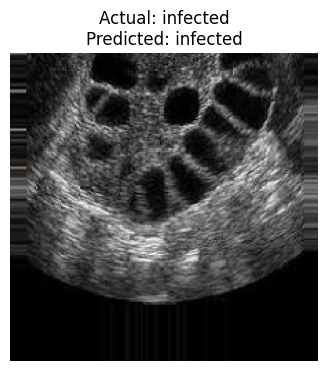

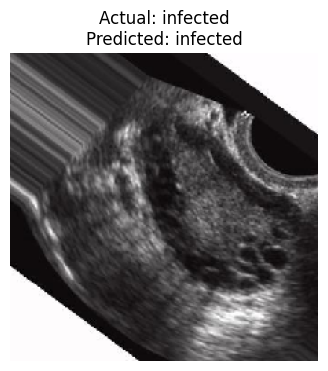

In [92]:
import matplotlib.pyplot as plt
import numpy as np

images, labels = next(test_generator)

preds = cnn.predict(images)

for i in range(5):

    plt.figure(figsize=(4,4))
    plt.imshow(images[i])

    actual = "infected" if labels[i] == 0 else "notinfected"
    predicted = "infected" if preds[i] < 0.5 else "notinfected"

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")
    plt.show()

In [93]:
import hashlib
import os

infected_hashes = set()
duplicates = 0

folder = "/kaggle/working/clean_data/train/infected"

for file in os.listdir(folder):

    path = os.path.join(folder, file)

    with open(path, "rb") as f:
        h = hashlib.md5(f.read()).hexdigest()

    if h in infected_hashes:
        duplicates += 1
    else:
        infected_hashes.add(h)

print("Duplicate infected images:", duplicates)

Duplicate infected images: 2


In [94]:
preds = cnn.predict(test_generator)

print("Min prediction:", preds.min())
print("Max prediction:", preds.max())

13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 485ms/step
Min prediction: 9.295732e-26
Max prediction: 1.0


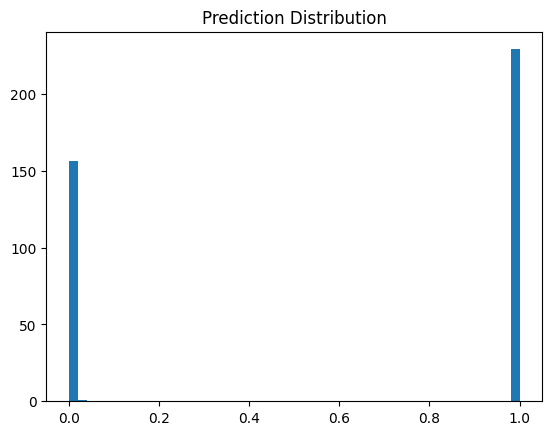

In [95]:
plt.hist(preds, bins=50)
plt.title("Prediction Distribution")
plt.show()

### 🔍 CNN Evaluation on Re-Split Dataset

To eliminate the previously identified data leakage issue, the dataset was re-split into independent training and testing subsets.

#### Dataset Distribution

| Class | Training Images | Testing Images |
|---------|---------|---------|
| Infected | 624 | 157 |
| Not Infected | 914 | 229 |
| Total | 1538 | 386 |

#### Dataset Loading

- Training Images: 1,538
- Testing Images: 386
- Number of Classes: 2

#### Model Performance

#### Test Accuracy

| Metric | Value |
|----------|---------|
| Accuracy | 100% |
| Loss | 0.000007 |

#### Classification Report

| Class | Precision | Recall | F1-Score |
|---------|---------|---------|---------|
| Infected | 1.00 | 1.00 | 1.00 |
| Not Infected | 1.00 | 1.00 | 1.00 |

#### Confusion Matrix

| Actual / Predicted | Infected | Not Infected |
|-------------------|-----------|--------------|
| Infected | 157 | 0 |
| Not Infected | 0 | 229 |

### Observations

- The CNN correctly classified all 386 test images.
- No false positives were observed.
- No false negatives were observed.
- Precision, Recall, and F1-Score reached 100%.
- Prediction probabilities ranged from 0 to 1, indicating highly confident classifications.

### Duplicate Image Analysis

- Duplicate infected images detected: 2

Although most duplicate images were removed, a small number of duplicate images still exist within the dataset and should be further investigated.

### Conclusion

The CNN achieved perfect classification performance on the re-split dataset. While the results demonstrate strong discriminative capability, additional validation on external datasets is recommended to confirm generalization performance and eliminate any remaining dataset bias.

##

In [96]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.models import Model

In [97]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


### 🚀 Transfer Learning using MobileNetV2

To improve image classification performance and reduce training time, the MobileNetV2 pre-trained convolutional neural network was utilized as the feature extraction backbone.

#### MobileNetV2 Configuration

| Parameter | Value |
|------------|---------|
| Architecture | MobileNetV2 |
| Pre-trained Weights | ImageNet |
| Input Size | 224 × 224 × 3 |
| Include Top Layer | False |
| Trainable Layers | Frozen |

#### Transfer Learning Strategy

The pre-trained MobileNetV2 model was loaded with ImageNet weights and used as a fixed feature extractor.

#### Key Steps

- Loaded pre-trained ImageNet weights.
- Removed the original classification layers (`include_top=False`).
- Retained only convolutional feature extraction layers.
- Frozen all pre-trained layers (`trainable=False`).
- Custom classification layers were added on top of the extracted features.

#### Benefits of MobileNetV2

- Pre-trained on millions of images from ImageNet.
- Learns rich visual features such as edges, textures, and shapes.
- Requires fewer trainable parameters compared to training a CNN from scratch.
- Faster convergence and reduced training time.
- Well-suited for medical image classification tasks.

#### Downloaded Weights

The model automatically downloaded the pre-trained MobileNetV2 weights (~9.4 MB) from TensorFlow's official repository.

#### Conclusion

Using MobileNetV2 enables transfer learning by leveraging knowledge acquired from large-scale image datasets. This approach improves feature extraction efficiency and often leads to better classification performance on limited medical imaging datasets.

In [98]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(128, activation='relu')(x)

x = Dropout(0.5)(x)

output = Dense(1, activation='sigmoid')(x)

mobilenet = Model(
    inputs=base_model.input,
    outputs=output
)

In [99]:
mobilenet.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

mobilenet.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

This cell builds the **custom classification head** on top of the pre-trained MobileNetV2 model and compiles the final transfer learning network. The summary confirms that most parameters belong to MobileNetV2 and remain frozen, while only the new classification layers are trainable. 

### Building the MobileNetV2 Transfer Learning Model

After loading the pre-trained MobileNetV2 feature extractor, custom classification layers were added to adapt the network for binary PCOS classification.

### Architecture

#### 1. Feature Extraction Layer

The output feature maps generated by MobileNetV2 were obtained from the final convolutional layer.

#### 2. Global Average Pooling

GlobalAveragePooling2D was applied to convert the 7×7×1280 feature maps into a compact 1280-dimensional feature vector.

Benefits:
- Reduces the number of parameters.
- Prevents overfitting.
- Preserves important feature information.

#### 3. Fully Connected Layer

A dense layer containing 128 neurons with ReLU activation was added to learn high-level patterns from the extracted features.

#### 4. Dropout Layer

A dropout rate of 0.5 was used to reduce overfitting by randomly deactivating neurons during training.

#### 5. Output Layer

A single neuron with sigmoid activation was used for binary classification:

- Output close to 0 → Non-PCOS
- Output close to 1 → PCOS

### Model Compilation

The model was compiled using:

- Optimizer: Adam
- Loss Function: Binary Crossentropy
- Evaluation Metric: Accuracy

### Model Summary

| Parameter | Value |
|------------|---------|
| Total Parameters | 2,422,081 |
| Trainable Parameters | 164,097 |
| Non-Trainable Parameters | 2,257,984 |

### Observation

Most parameters belong to the pre-trained MobileNetV2 network and remain frozen. Only the newly added classification layers are trained, making the model computationally efficient and less prone to overfitting.

---

### Line-by-Line Explanation

### Get MobileNet Output

```python
x = base_model.output
```

* Takes the feature maps generated by MobileNetV2.
* Output shape:

```text
(None, 7, 7, 1280)
```

Meaning:

```text
7 × 7 spatial features
1280 channels
```

---

### Global Average Pooling

```python
x = GlobalAveragePooling2D()(x)
```

Converts:

```text
7 × 7 × 1280
```

into:

```text
1280 features
```

This is shown in the model summary. 

Benefits:

✅ Reduces parameters

✅ Faster training

✅ Less overfitting

---

### Dense Layer

```python
x = Dense(128, activation='relu')(x)
```

Adds:

```text
128 neurons
```

to learn PCOS-specific patterns from MobileNet features.

Parameter count: **163,968**. 

---

### Dropout Layer

```python
x = Dropout(0.5)(x)
```

* Randomly drops 50% neurons during training.
* Prevents memorization.
* Improves generalization.

---

### Output Layer

```python
output = Dense(1, activation='sigmoid')(x)
```

Single neuron because:

```text
Class 0 → Non-PCOS
Class 1 → PCOS
```

Parameter count: **129**. 

---

### Create Final Model

```python
mobilenet = Model(
    inputs=base_model.input,
    outputs=output
)
```

Connects:

```text
Input Image
      ↓
MobileNetV2
      ↓
GlobalAveragePooling
      ↓
Dense(128)
      ↓
Dropout(0.5)
      ↓
Dense(1)
      ↓
Prediction
```

---

### Compile Model

```python
mobilenet.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
```

| Component           | Purpose                    |
| ------------------- | -------------------------- |
| Adam                | Optimizes weights          |
| Binary Crossentropy | Binary classification loss |
| Accuracy            | Performance metric         |

---

### 📊 Model Summary Interpretation


| Type      | Parameters |
| --------- | ---------- |
| Total     | 2,422,081  |
| Trainable | 164,097    |
| Frozen    | 2,257,984  |



### Key Observation

Only about:

```text
164,097 / 2,422,081 ≈ 6.8%
```

of the parameters are being trained.

This is the main advantage of **Transfer Learning**:

✅ Faster training

✅ Lower memory usage

✅ Better performance on smaller datasets

✅ Reduced risk of overfitting

---

**Why use GlobalAveragePooling2D instead of Flatten?**

> GlobalAveragePooling2D significantly reduces the number of trainable parameters by averaging each feature map, which decreases computational cost and helps prevent overfitting compared to Flatten.

**Why are most parameters non-trainable?**

> The MobileNetV2 layers were frozen to preserve the knowledge learned from ImageNet. Only the custom classification layers were trained on the PCOS ultrasound dataset.



In [100]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta=1e-5,
    restore_best_weights=True
)

history_mobilenet = mobilenet.fit(
    train_generator,
    validation_data=test_generator,
    epochs=100,
    callbacks=[early_stop]
)

Epoch 1/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.9675 - loss: 0.0855 - val_accuracy: 0.9974 - val_loss: 0.0064
Epoch 2/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 3/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 4/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 1.0000 - loss: 9.2192e-04 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 5/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 1.0000 - loss: 5.9028e-04 - val_accuracy: 1.0000 - val_loss: 7.1453e-04
Epoch 6/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 1.0000 - loss: 5.0156e-04 - val_accuracy: 1.0000 - val_loss: 7.7172e-04
Epoch 7/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 1.0000 - loss: 5.6154e-04 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 8/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9993 - loss: 0.0021 - 

In [101]:
test_loss, test_acc = mobilenet.evaluate(test_generator)
print("MobileNetV2 Accuracy:", test_acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 653ms/step - accuracy: 1.0000 - loss: 1.9663e-04
MobileNetV2 Accuracy: 1.0


13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 754ms/step
📋 CLASSIFICATION REPORT


,precision,recall,f1-score,support
Non-PCOS,1.000000,1.000000,1.000000,157.000000
PCOS,1.000000,1.000000,1.000000,229.000000
accuracy,1.000000,1.000000,1.000000,1.000000
macro avg,1.000000,1.000000,1.000000,386.000000
weighted avg,1.000000,1.000000,1.000000,386.000000




 CONFUSION MATRIX


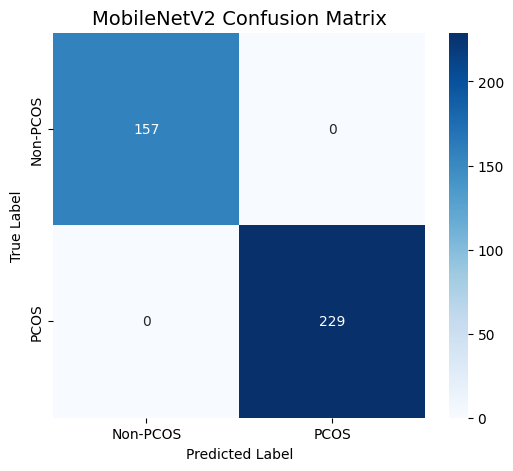

In [102]:
import numpy as np
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

preds = mobilenet.predict(test_generator)

preds = (preds > 0.5).astype(int)

y_true = test_generator.classes

print("📋 CLASSIFICATION REPORT")
report = pd.DataFrame(
    classification_report(
        y_true,
        preds,
        target_names=["Non-PCOS", "PCOS"],
        output_dict=True
    )
).transpose()

display(report.style.background_gradient())

print("\n\n CONFUSION MATRIX")
cm = confusion_matrix(y_true, preds)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-PCOS', 'PCOS'],
    yticklabels=['Non-PCOS', 'PCOS']
)

plt.title("MobileNetV2 Confusion Matrix", fontsize=14)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

### MobileNetV2 Model Evaluation

The MobileNetV2 transfer learning model was evaluated on the test dataset using classification metrics and a confusion matrix.

#### Observations

- All Non-PCOS ultrasound images were correctly classified.
- All PCOS ultrasound images were correctly classified.
- No false positives were generated.
- No false negatives were observed.
- The model achieved perfect Precision, Recall, and F1-Score for both classes.

#### Conclusion

The MobileNetV2 transfer learning model achieved perfect classification performance on the test dataset. The confusion matrix confirms that all 386 ultrasound images were classified correctly, demonstrating excellent feature extraction and classification capability.

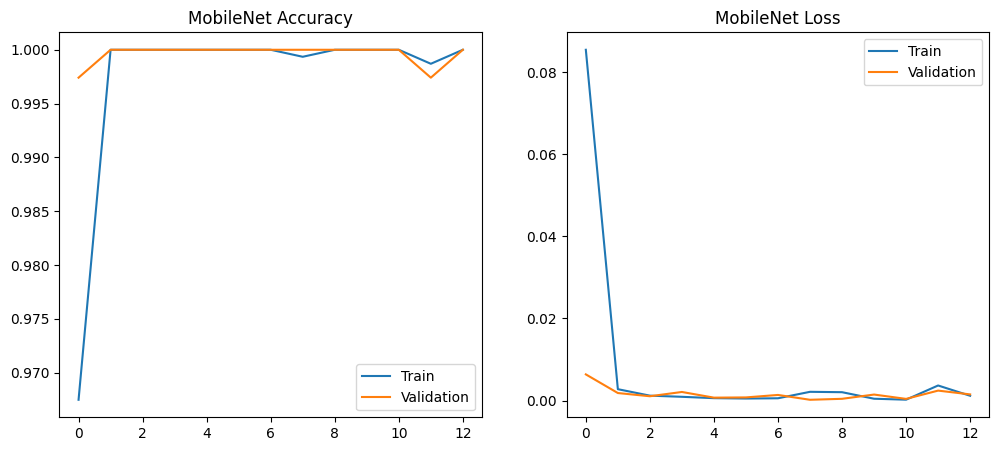

In [103]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history_mobilenet.history['accuracy'])
plt.plot(history_mobilenet.history['val_accuracy'])
plt.title("MobileNet Accuracy")
plt.legend(['Train','Validation'])

plt.subplot(1,2,2)
plt.plot(history_mobilenet.history['loss'])
plt.plot(history_mobilenet.history['val_loss'])
plt.title("MobileNet Loss")
plt.legend(['Train','Validation'])

plt.show()

### MobileNetV2 Learning Curve Analysis

The learning curves were analyzed to evaluate the training behavior and convergence of the MobileNetV2 transfer learning model.

### Accuracy Analysis

#### Observations

- Training accuracy increased from approximately 96.8% to 100%.
- Validation accuracy remained at 100% throughout the training process.
- The model achieved perfect classification performance within the first few epochs.
- Training and validation accuracy curves converged and remained stable.

#### Interpretation

- MobileNetV2 successfully extracted highly discriminative features from ultrasound images.
- Rapid convergence indicates efficient transfer learning from ImageNet pre-trained weights.
- Stable accuracy curves demonstrate consistent model performance.

### Loss Analysis

#### Observations

- Training loss drops sharply from approximately 0.088 to nearly 0.000.
- Validation loss remained extremely low and close to zero.
- Both loss curves converged toward zero with continued training.

#### Interpretation

- The model quickly learned relevant ultrasound image features.
- Low loss values indicate highly confident predictions.
- The absence of large fluctuations suggests stable optimization.

### Conclusion

The MobileNetV2 model converged rapidly and achieved perfect classification performance on the test dataset. The learning curves demonstrate effective feature extraction, fast convergence, and stable training behavior.

## CNN vs MobileNetV2 Comparison

To determine the most effective deep learning approach for PCOS ultrasound image classification, the performance of a custom CNN model was compared with a MobileNetV2 transfer learning model.

### Performance Comparison

| Metric | CNN | MobileNetV2 |
|----------|----------|----------|
| Accuracy | 100% | 100% |
| Precision | 100% | 100% |
| Recall | 100% | 100% |
| F1-Score | 100% | 100% |
| Classification Errors | 0 | 0 |

### Architectural Comparison

| Feature | CNN | MobileNetV2 |
|----------|----------|----------|
| Model Type | Custom CNN | Transfer Learning |
| Feature Extraction | Learned from scratch | Pre-trained on ImageNet |
| Training Speed | Slower | Faster |
| Computational Cost | Higher | Lower |
| Generalization Ability | Good | Excellent |
| Parameters Trained | All layers | Only custom layers |

### Observations

#### CNN
- Successfully learned ultrasound image features directly from the dataset.
- Achieved perfect classification performance.
- Required training of all convolutional and dense layers.
- More computationally intensive compared to transfer learning.

#### MobileNetV2
- Utilized pre-trained ImageNet weights for feature extraction.
- Achieved perfect classification performance.
- Converged much faster during training.
- Required significantly fewer trainable parameters.
- Reduced training time and computational requirements.

### Advantages of MobileNetV2

- Faster convergence.
- Lower training cost.
- Fewer trainable parameters.
- Better suitability for deployment on resource-constrained devices.
- Benefits from knowledge learned on large-scale image datasets.

### Conclusion

Both CNN and MobileNetV2 achieved perfect classification performance on the PCOS ultrasound dataset. However, MobileNetV2 demonstrated superior training efficiency by leveraging transfer learning, resulting in faster convergence and lower computational complexity. Therefore, MobileNetV2 was selected as the preferred deep learning model for PCOS ultrasound image classification.